<div dir="rtl" style="text-align: right;">
<h3>1 کتابخانه‌ها و نمودار</h3>
</div>

In [1]:
import os
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import plotly.express as px
import plotly.io as pio
import matplotlib.pyplot as plt
import seaborn as sns
from dotenv import load_dotenv
from scipy import stats
from sqlalchemy import URL, create_engine, text
from statsmodels.stats.proportion import proportions_ztest

pio.templates.default = 'plotly_dark'
pio.renderers.default = 'notebook'
pd.set_option('display.max_columns', 40)
pd.set_option('display.float_format', '{:.3f}'.format)

current_dir = Path.cwd().resolve()

ROOT = next(
    (
        path
        for path in [current_dir, *current_dir.parents]
        if (path / "notebooks" / "nba_analysis.ipynb").is_file()
    ),
    None,
)

if ROOT is None:
    raise FileNotFoundError(
        "Project root was not found. Run the notebook from within the repository."
    )

notebooks_dir = str(ROOT / "notebooks")

if notebooks_dir not in sys.path:
    sys.path.insert(0, notebooks_dir)

import nba_top_players

load_dotenv(ROOT / ".env")

DB_PATH = ROOT / "database" / "data" / "nba_star.db"

if not DB_PATH.is_file():
    raise FileNotFoundError(f"Database file was not found: {DB_PATH}")

<div dir="rtl" style="text-align: right;">
<h3>1.1 آزمون فرض</h3>
</div>

<div dir="rtl" style="text-align: right;">
<h2>2. خواندن داده‌ها</h2>
</div>

In [2]:
engine = create_engine(
    URL.create("sqlite", database=str(DB_PATH))
)

with engine.connect() as connection:
    integrity_result = connection.execute(
        text("PRAGMA integrity_check")
    ).scalars().all()

    table_names = connection.execute(
        text(
            "SELECT name FROM sqlite_master "
            "WHERE type = 'table' ORDER BY name"
        )
    ).scalars().all()

if integrity_result != ["ok"]:
    raise RuntimeError(f"Database integrity check failed: {integrity_result}")

required_tables = {
    "fact_player_stats",
    "dim_player",
    "dim_season",
    "dim_team_scope",
    "dim_player_context",
    "dim_phase",
}

missing_tables = required_tables - set(table_names)

if missing_tables:
    raise RuntimeError(f"Required tables are missing: {sorted(missing_tables)}")

print(f"Database: {DB_PATH}")
print("Integrity check: OK")
print(f"Tables: {len(table_names)}")

Database: G:\بوت کمپ تحلیل داده\New folder\github\nba-data-analysis\database\data\nba_star.db
Integrity check: OK
Tables: 9


<div dir="rtl" style="text-align: right;">
<h2>3. پاک‌سازی داده‌ها</h2>
<h3>3.1 داده های خالی</h3>

</div>

In [3]:
df_dim_player = pd.read_sql('SELECT * from dim_player',engine)
print(df_dim_player.info())

<class 'pandas.DataFrame'>
RangeIndex: 964 entries, 0 to 963
Data columns (total 6 columns):
 #   Column                Non-Null Count  Dtype
---  ------                --------------  -----
 0   player_key            964 non-null    int64
 1   source_player_id      964 non-null    int64
 2   player_name           964 non-null    str  
 3   birth_date            964 non-null    str  
 4   listed_height_inches  964 non-null    int64
 5   listed_weight_pounds  964 non-null    int64
dtypes: int64(4), str(2)
memory usage: 45.3 KB
None


In [4]:
df_dim_player_context = pd.read_sql('SELECT * from dim_player_context',engine)
print(df_dim_player_context.info())

<class 'pandas.DataFrame'>
RangeIndex: 538 entries, 0 to 537
Data columns (total 4 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   context_key       538 non-null    int64
 1   reported_age      538 non-null    int64
 2   experience_years  538 non-null    int64
 3   position_code     538 non-null    str  
dtypes: int64(3), str(1)
memory usage: 16.9 KB
None


In [5]:
df_dim_team_scope = pd.read_sql('SELECT * from dim_team_scope',engine)
print(df_dim_team_scope.info())

<class 'pandas.DataFrame'>
RangeIndex: 33 entries, 0 to 32
Data columns (total 6 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   scope_key             33 non-null     int64  
 1   scope_code            33 non-null     str    
 2   scope_kind            33 non-null     str    
 3   source_team_id        30 non-null     float64
 4   team_name             30 non-null     str    
 5   aggregate_team_count  3 non-null      float64
dtypes: float64(2), int64(1), str(3)
memory usage: 1.7 KB
None


In [6]:
df_fact_mvp_voting = pd.read_sql('SELECT * from fact_mvp_voting',engine)
print(df_fact_mvp_voting.info())

<class 'pandas.DataFrame'>
RangeIndex: 61 entries, 0 to 60
Data columns (total 9 columns):
 #   Column                         Non-Null Count  Dtype
---  ------                         --------------  -----
 0   mvp_vote_key                   61 non-null     int64
 1   player_key                     61 non-null     int64
 2   season_key                     61 non-null     int64
 3   scope_key                      61 non-null     int64
 4   phase_key                      61 non-null     int64
 5   context_key                    61 non-null     int64
 6   source_representative_stat_id  61 non-null     int64
 7   first_place_votes              61 non-null     int64
 8   voting_points_won              61 non-null     int64
dtypes: int64(9)
memory usage: 4.4 KB
None


In [7]:
df_fact_player_salary = pd.read_sql('SELECT * from fact_player_salary',engine)
print(df_fact_player_salary.info())

<class 'pandas.DataFrame'>
RangeIndex: 2614 entries, 0 to 2613
Data columns (total 4 columns):
 #   Column             Non-Null Count  Dtype
---  ------             --------------  -----
 0   salary_key         2614 non-null   int64
 1   player_key         2614 non-null   int64
 2   season_key         2614 non-null   int64
 3   annual_salary_usd  2614 non-null   int64
dtypes: int64(4)
memory usage: 81.8 KB
None


In [8]:
df_fact_player_stats = pd.read_sql('SELECT * from fact_player_stats',engine)
print(df_fact_player_stats.info())

<class 'pandas.DataFrame'>
RangeIndex: 4686 entries, 0 to 4685
Data columns (total 48 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   stat_key                       4686 non-null   int64  
 1   source_stat_id                 4686 non-null   int64  
 2   player_key                     4686 non-null   int64  
 3   season_key                     4686 non-null   int64  
 4   scope_key                      4686 non-null   int64  
 5   phase_key                      4686 non-null   int64  
 6   context_key                    4686 non-null   int64  
 7   totals_source_rank             4686 non-null   int64  
 8   advanced_source_rank           4686 non-null   int64  
 9   is_player_phase_total          4686 non-null   int64  
 10  awards_source_text             4686 non-null   str    
 11  games_played                   4686 non-null   int64  
 12  games_started                  4686 non-null   int64  
 13 

In [9]:
df_fact_roster = pd.read_sql('SELECT * from fact_roster',engine)
print(df_fact_roster.info())

<class 'pandas.DataFrame'>
RangeIndex: 3203 entries, 0 to 3202
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   roster_key   3203 non-null   int64
 1   player_key   3203 non-null   int64
 2   season_key   3203 non-null   int64
 3   scope_key    3203 non-null   int64
 4   context_key  3203 non-null   int64
dtypes: int64(5)
memory usage: 125.2 KB
None


<div dir="rtl" style="text-align: right;">
<h3>3.2 داده‌های پرت</h3>
</div>

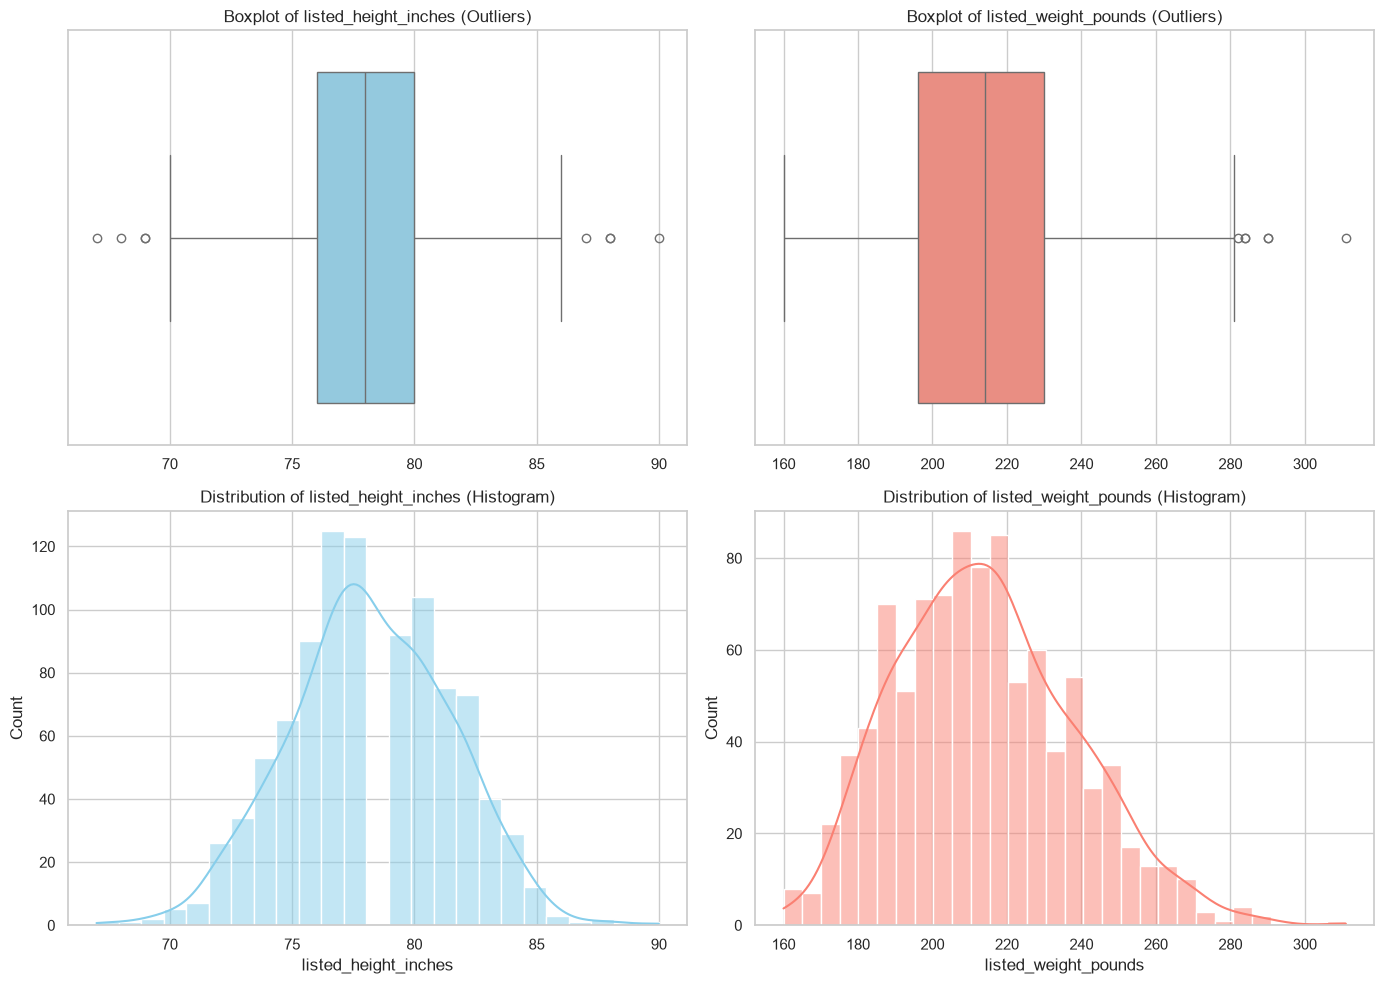

In [10]:
# ================================
# df_dim_plyer outliers
# ================================

sns.set_theme(style="whitegrid")

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# ----- listed_height_inches-----
# 1.Box Plot
sns.boxplot(x=df_dim_player['listed_height_inches'], ax=axes[0, 0], color='skyblue')
axes[0, 0].set_title(f'Boxplot of {'listed_height_inches'} (Outliers)')
axes[0, 0].set(xlabel='')

# 2.Hist Plot
sns.histplot(df_dim_player['listed_height_inches'], kde=True, ax=axes[1, 0], color='skyblue', bins=25)
axes[1, 0].set_title(f'Distribution of {'listed_height_inches'} (Histogram)')

# -----listed_weight_pounds-----
# 1.Box Plot
sns.boxplot(x=df_dim_player['listed_weight_pounds'], ax=axes[0, 1], color='salmon')
axes[0, 1].set_title(f'Boxplot of {'listed_weight_pounds'} (Outliers)')
axes[0, 1].set(xlabel='')

# 2.Hist Plot
sns.histplot(df_dim_player['listed_weight_pounds'], kde=True, ax=axes[1, 1], color='salmon', bins=30)
axes[1, 1].set_title(f'Distribution of {'listed_weight_pounds'} (Histogram)')

plt.tight_layout()
plt.show()

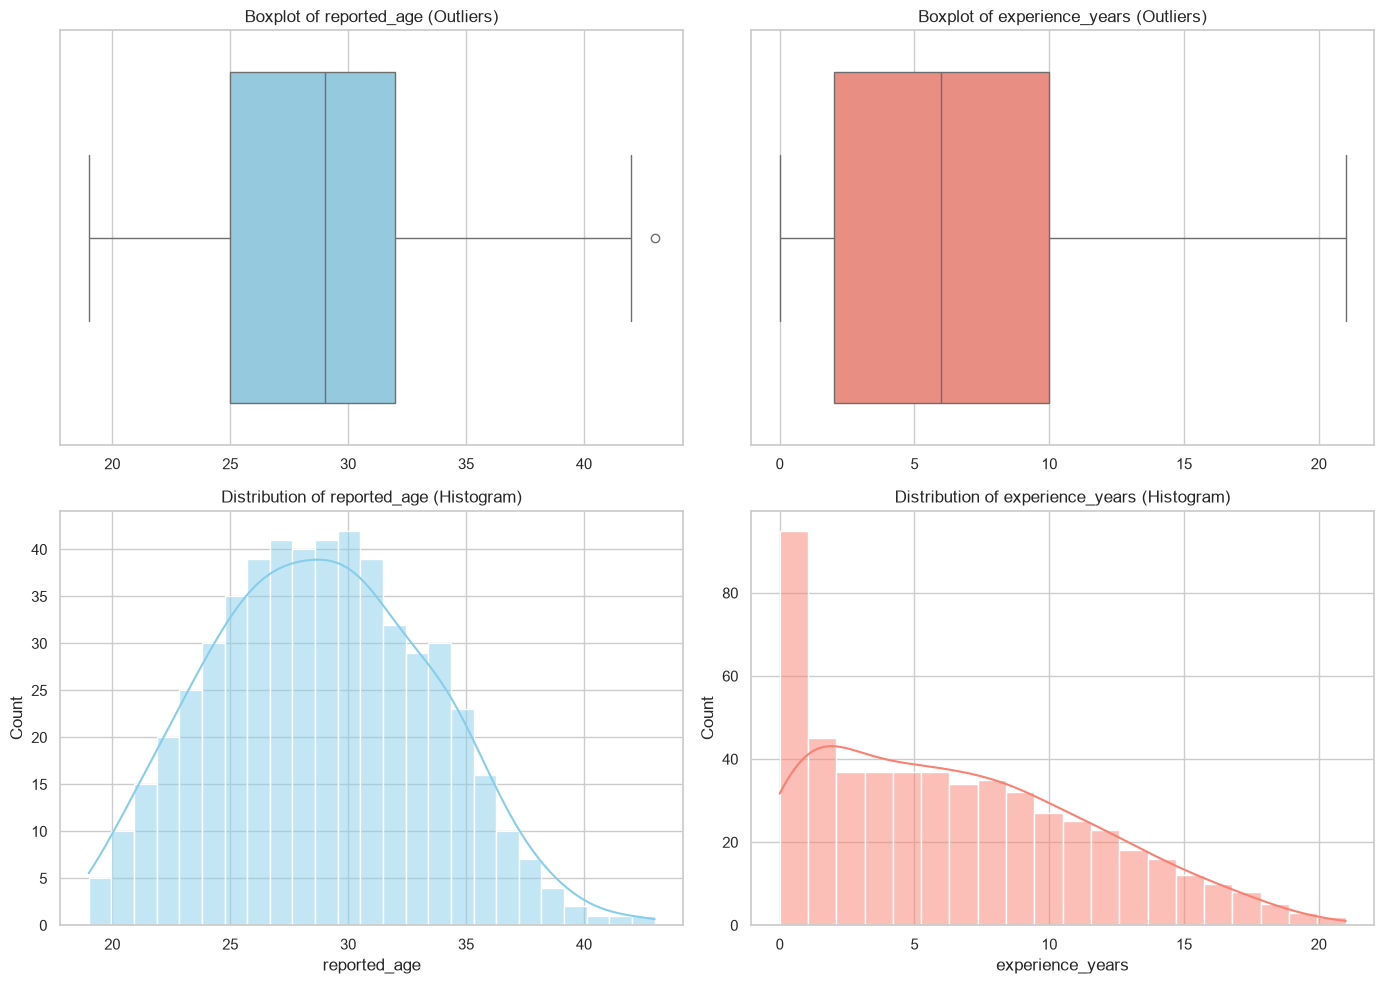

In [11]:
# ================================
# df_dim_plyer_context outliers
# ================================

sns.set_theme(style="whitegrid")

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# ----- reported_age-----
# 1.Box Plot
sns.boxplot(x=df_dim_player_context['reported_age'], ax=axes[0, 0], color='skyblue')
axes[0, 0].set_title(f'Boxplot of {'reported_age'} (Outliers)')
axes[0, 0].set(xlabel='')

# 2.Hist Plot
sns.histplot(df_dim_player_context['reported_age'], kde=True, ax=axes[1, 0], color='skyblue', bins=25)
axes[1, 0].set_title(f'Distribution of {'reported_age'} (Histogram)')

# -----experience_years-----
# 1.Box Plot
sns.boxplot(x=df_dim_player_context['experience_years'], ax=axes[0, 1], color='salmon')
axes[0, 1].set_title(f'Boxplot of {'experience_years'} (Outliers)')
axes[0, 1].set(xlabel='')

# 2.Hist Plot
sns.histplot(df_dim_player_context['experience_years'], kde=True, ax=axes[1, 1], color='salmon', bins=20)
axes[1, 1].set_title(f'Distribution of {'experience_years'} (Histogram)')

plt.tight_layout()
plt.show()

Text(0.5, 1.0, 'Distribution of annual_salary_usd (Histogram)')

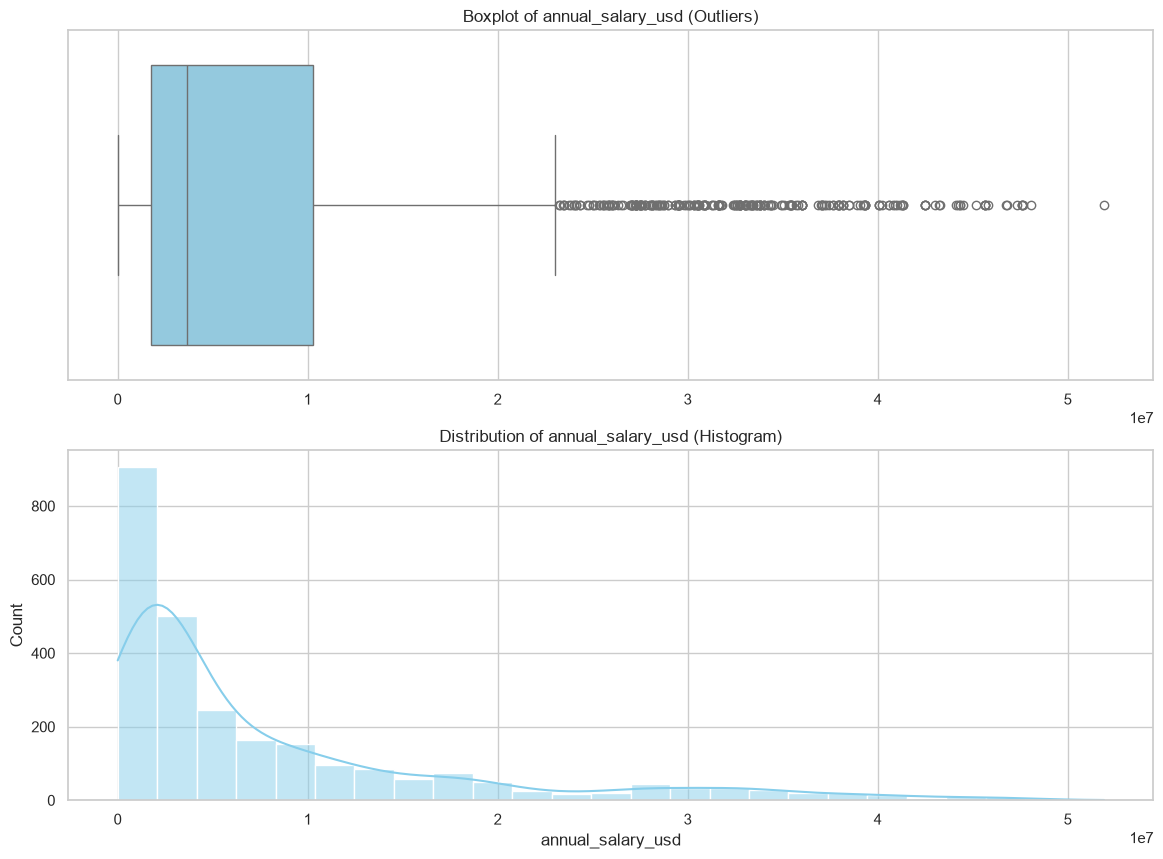

In [12]:
# ================================
# df_dim_plyer_salary outliers
# ================================

sns.set_theme(style="whitegrid")

fig, axes = plt.subplots(2, figsize=(14, 10))

# ----- annual_salary_usd-----
# 1.Box Plot
sns.boxplot(x=df_fact_player_salary['annual_salary_usd'], ax=axes[0], color='skyblue')
axes[0].set_title(f'Boxplot of {'annual_salary_usd'} (Outliers)')
axes[0].set(xlabel='')

# 2.Hist Plot
sns.histplot(df_fact_player_salary['annual_salary_usd'], kde=True, ax=axes[1], color='skyblue', bins=25)
axes[1].set_title(f'Distribution of {'annual_salary_usd'} (Histogram)')



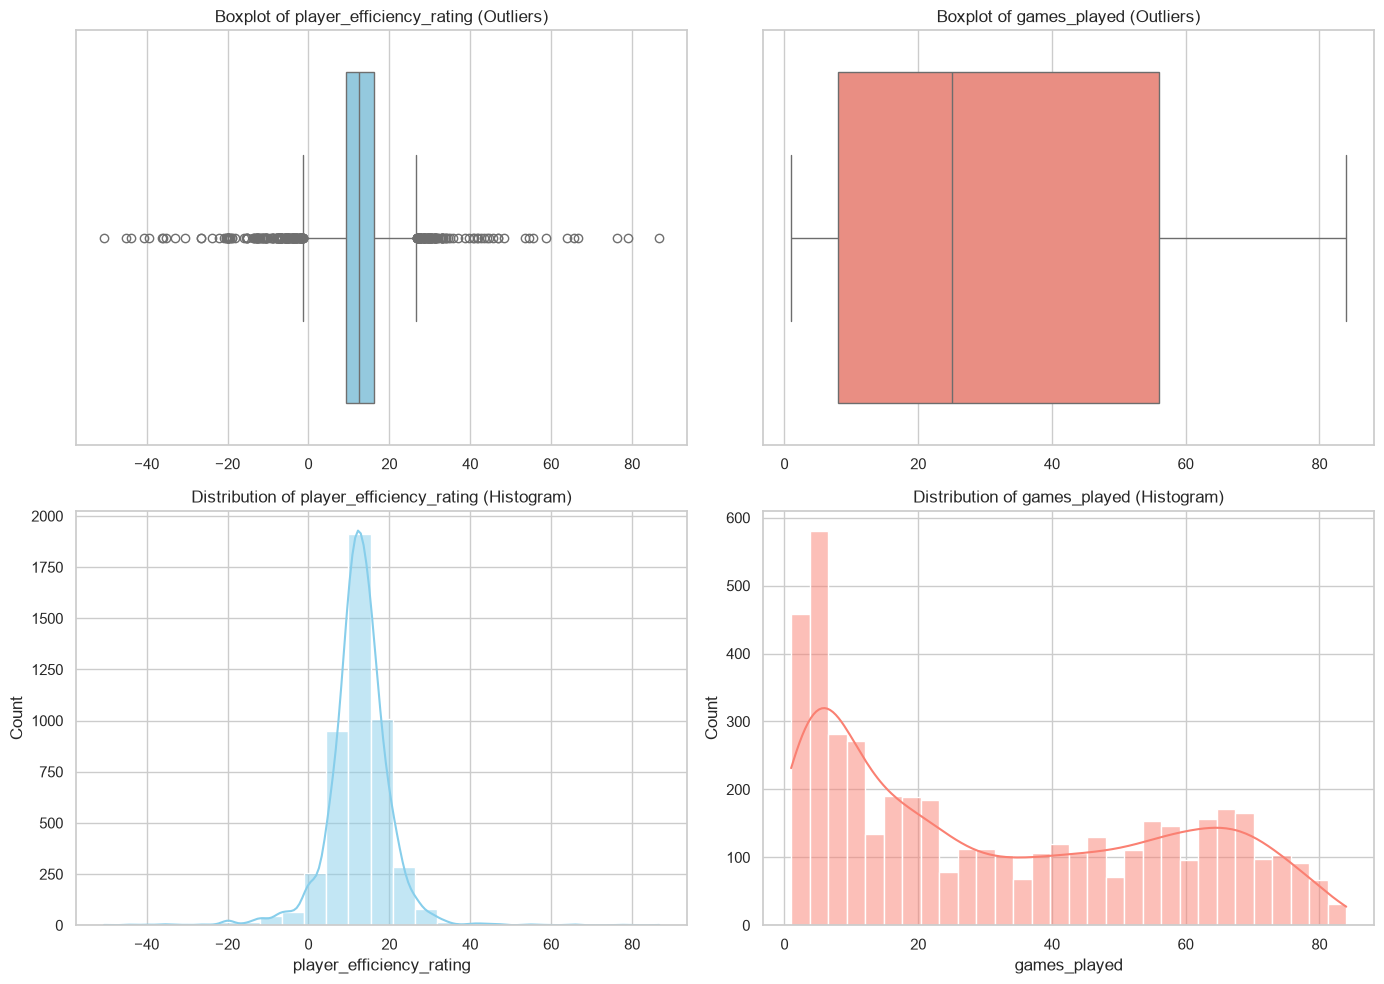

In [13]:
# ================================
# df_fact_player_stats outliers
# ================================

sns.set_theme(style="whitegrid")

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# ----- player_efficiency_rating-----
# 1.Box Plot
sns.boxplot(x=df_fact_player_stats['player_efficiency_rating'], ax=axes[0, 0], color='skyblue')
axes[0, 0].set_title(f'Boxplot of {'player_efficiency_rating'} (Outliers)')
axes[0, 0].set(xlabel='')

# 2.Hist Plot
sns.histplot(df_fact_player_stats['player_efficiency_rating'],kde=True, ax=axes[1, 0],color='skyblue',bins=25)
axes[1, 0].set_title(f'Distribution of {'player_efficiency_rating'} (Histogram)')

# -----games_played-----
# 1.Box Plot
sns.boxplot(x=df_fact_player_stats['games_played'], ax=axes[0, 1], color='salmon')
axes[0, 1].set_title(f'Boxplot of {'games_played'} (Outliers)')
axes[0, 1].set(xlabel='')

# 2.Hist Plot
sns.histplot(df_fact_player_stats['games_played'], kde=True, ax=axes[1, 1], color='salmon', bins=30)
axes[1, 1].set_title(f'Distribution of {'games_played'} (Histogram)')

plt.tight_layout()
plt.show()

<div dir="rtl" style="text-align: right;">
<h3>3.3 بازیکنان واجد شرایط و فعال</h3>
</div>

<div dir="rtl" style="text-align: right;">
<h2>4. شناخت داده‌ها</h2>
<h3>4.1 ویژگی‌های بدنی</h3>
</div>

<div dir="rtl" style="text-align: right;">
<h3>4.2 عملکرد بازیکنان</h3>
</div>

<div dir="rtl" style="text-align: right;">
<h3>4.3 تیم‌ها و قهرمانان</h3>
</div>

<div dir="rtl" style="text-align: right;">
<h3>4.4 رابطه میان آمار بازیکنان</h3>
</div>

<div dir="rtl" style="text-align: right;">
<h3>4.5 مقایسه پست‌ها در پنج فصل</h3>
</div>

<div dir="rtl" style="text-align: right;">
<h2>5. معیار انتخاب بازیکنان برتر</h2>
</div>

<div dir="rtl" style="text-align: right;">

### هدف
برای هر فصل، بازیکنان را با یک **امتیاز واحد** رتبه‌بندی می‌کنیم و 50 نفر اول را انتخاب می‌کنیم.

### چرا یک امتیاز ترکیبی؟
هیچ آمار منفردی عملکرد را کامل نشان نمی‌دهد. برای مثال، مجموع امتیاز به تعداد شوت‌ها وابسته است و کیفیتِ بازی در هر دقیقه را نشان نمی‌دهد. به همین دلیل دو دیدگاه را با هم ترکیب کردیم:

- **شاخص‌های نرخی (کیفیت در هر دقیقه):**
  - **BPM** (Box Plus/Minus): تخمین امتیازی که بازیکن در هر 100 حمله نسبت به یک بازیکن متوسط اضافه می‌کند (صفر = متوسط).
  - **PER** (Player Efficiency Rating): نسبت کارهای مثبت (امتیاز، ریباند، پاس گل، سرقت، بلاک) به کارهای منفی (شوت از دست رفته، توپ‌باخت، خطا) در هر دقیقه؛ میانگین لیگ حدود 15 است.
  - **WS/48** (Win Shares per 48 minutes): سهم بازیکن در بردهای تیم به ازای 48 دقیقه؛ میانگین لیگ حدود 0.1 است.
- **شاخص حجمی (مجموع ارزش در کل فصل):**
  - **WS** (Win Shares): تعداد بردهایی که بازیکن در کل فصل برای تیمش ساخته است. این شاخص باعث می‌شود بازیکنی که نیمی از فصل را غایب بوده، فقط به خاطر نرخ بالا در صدر نیاید.

### مراحل محاسبه
1. فقط **فصل عادی** و **یک ردیف برای هر بازیکن**؛ برای بازیکنانی که وسط فصل تیم عوض کرده‌اند، ردیف مجموعِ همهٔ تیم‌ها (2TM/3TM) استفاده می‌شود.
2. فقط بازیکنان با **حداقل 1000 دقیقه** بازی؛ زیرا آمار نمونه‌های کوچک پرنوسان است و بازیکن با چند دقیقه بازیِ عالی نباید قهرمان شود.
3. **استانداردسازی (z-score)** هر شاخص در همان فصل: 
   $z(x)=\dfrac{x-\mu}{\sigma}$ 
   که $\mu$ و $\sigma$ میانگین و انحراف معیار همان شاخص بین بازیکنان واجد شرایط آن فصل است. این کار شاخص‌هایی با مقیاس‌های متفاوت را قابل جمع می‌کند.
4. محاسبهٔ امتیاز نهایی:

$$\text{Impact}=\frac{z(\text{BPM})+z(\text{PER})+z(\text{WS/48})}{3}$$

$$\text{Score}=0.6\times\text{Impact}+0.4\times z(\text{WS})$$

5. مرتب‌سازی نزولی بر اساس Score و انتخاب 50 نفر اول.

### چرا وزن‌های 0.6 و 0.4؟
کیفیت در هر دقیقه نشانهٔ اصلی توانایی است (وزن بیشتر)، ولی میزان حضور در فصل هم مهم است. این وزن‌ها یک **تصمیم قضاوتی** هستند، نه فرمول «درستِ مطلق»؛ به همین دلیل حساسیت‌سنجی انجام دادیم.


</div>


In [14]:
top50 = nba_top_players.get_top_players(engine, "2019-20")        # or just pass the path :)))
# all_years = pd.concat([nba_top_players.get_top_players(engine, s) for s in
#                        ["2019-20","2020-21","2021-22","2022-23","2023-24"]])
top50

,rank,player_key,player_name,season,team,position,games_played,minutes_played,box_plus_minus,player_efficiency_rating,win_shares_per_48_minutes,win_shares,impact_z,volume_z,score
0,1,313,Giannis Antetokounmpo,2019-20,MIL,PF,63,1917,11.500,31.900,0.279,11.100,3.602,3.201,3.442
1,2,410,James Harden,2019-20,HOU,SG,68,2483,9.600,29.100,0.254,13.100,3.014,4.071,3.437
2,3,47,Anthony Davis,2019-20,LAL,PF,62,2131,8.000,27.400,0.250,11.100,2.669,3.201,2.881
3,4,176,Damian Lillard,2019-20,POR,PG,66,2474,7.500,26.900,0.225,11.600,2.421,3.418,2.820
4,5,602,LeBron James,2019-20,LAL,PG,67,2316,8.400,25.500,0.204,9.800,2.306,2.635,2.438
5,6,539,Kawhi Leonard,2019-20,LAC,SF,57,1848,8.900,26.900,0.226,8.700,2.601,2.157,2.423
6,7,616,Luka Dončić,2019-20,DAL,PG,61,2047,8.400,27.600,0.207,8.800,2.476,2.200,2.365
7,8,722,Nikola Jokić,2019-20,DEN,C,73,2336,7.400,24.900,0.202,9.800,2.127,2.635,2.330
8,9,799,Rudy Gobert,2019-20,UTA,C,68,2333,3.600,21.700,0.221,10.700,1.537,3.027,2.133
9,10,459,Jimmy Butler,2019-20,MIA,SF,58,1959,5.400,23.600,0.221,9.000,1.898,2.287,2.053


<div dir="rtl" style="text-align: right;">
<h2>6. آمار توصیفی</h2>
<h3>6.1 قد نامزدهای MVP و بازیکنان برتر</h3>
</div>

<div dir="rtl" style="text-align: right;">
<h3>6.2 تجربه و قد بازیکنان تیم قهرمان</h3>
</div>

In [ ]:
mvp_in_22_23 = pd.read_sql('SELECT listed_height_inches,experience_years from fact_mvp_voting INNER JOIN dim_player ON fact_mvp_voting.player_key = dim_player.player_key INNER JOIN dim_player_context ON fact_mvp_voting.context_key = dim_player_context.context_key where season_key = 4'
                           ,engine)
mvp_in_23_24 = pd.read_sql('SELECT listed_height_inches,experience_years from fact_mvp_voting INNER JOIN dim_player ON fact_mvp_voting.player_key = dim_player.player_key INNER JOIN dim_player_context ON fact_mvp_voting.context_key = dim_player_context.context_key where season_key = 5'
                           ,engine)
champ_players_22_23 = pd.read_sql('SELECT fact_roster.player_key,experience_years,listed_height_inches  from (SELECT dim_season.season_key,dim_team_scope.scope_key from dim_season INNER JOIN dim_team_scope ON dim_season.champion_team_name = dim_team_scope.team_name WHERE season_key = 4) AS sub INNER JOIN fact_roster ON sub.season_key = fact_roster.season_key INNER JOIN dim_player_context ON dim_player_context.context_key = fact_roster.context_key INNER JOIN dim_player ON dim_player.player_key = fact_roster.player_key WHERE fact_roster.scope_key = sub.scope_key'
                                  ,engine)
champ_players_23_24 = pd.read_sql('SELECT fact_roster.player_key,experience_years,listed_height_inches  from (SELECT dim_season.season_key,dim_team_scope.scope_key from dim_season INNER JOIN dim_team_scope ON dim_season.champion_team_name = dim_team_scope.team_name WHERE season_key = 5) AS sub INNER JOIN fact_roster ON sub.season_key = fact_roster.season_key INNER JOIN dim_player_context ON dim_player_context.context_key = fact_roster.context_key INNER JOIN dim_player ON dim_player.player_key = fact_roster.player_key WHERE fact_roster.scope_key = sub.scope_key'
                                  ,engine)
# champ_players_23_24_1 = pd.read_sql('SELECT distinct fact_roster.player_key,experience_years,listed_height_inches  from (SELECT dim_season.season_key,dim_team_scope.scope_key from dim_season INNER JOIN dim_team_scope ON dim_season.champion_team_name = dim_team_scope.team_name WHERE season_key = 5) AS sub INNER JOIN fact_roster ON sub.season_key = fact_roster.season_key INNER JOIN dim_player_context ON dim_player_context.context_key = fact_roster.context_key INNER JOIN dim_player ON dim_player.player_key = fact_roster.player_key INNER JOIN fact_player_stats ON fact_roster.player_key = fact_player_stats.player_key WHERE fact_roster.scope_key = sub.scope_key'
#  ,engine)


,player_key,experience_years,listed_height_inches
0,16,16,80
1,173,2,80
2,226,6,76
3,253,0,80
4,361,1,73
5,379,2,76
6,436,7,78
7,442,6,80
8,497,0,78
9,512,14,76


<div dir="rtl" style="text-align: right;">
<h3>6.3 پیشنهاد پوینت‌گارد</h3>
</div>

<div dir="rtl" style="text-align: right;">
<h2>7. آزمون فرض</h2>
<h3>7.1 تغییر چابکی بازیکنان برتر</h3>
</div>

<div dir="rtl" style="text-align: right;">
<h3>7.2 تجربه بازیکنان تیم قهرمان</h3>
</div>

<div dir="rtl" style="text-align: right;">
<h2>8. تحلیل‌های تکمیلی</h2>
<h3>8.1 تحلیل تکمیلی اول</h3>
</div>

<div dir="rtl" style="text-align: right;">
<h3>8.2 تحلیل تکمیلی دوم</h3>
</div>

<div dir="rtl" style="text-align: right;">
<h3>8.3 تحلیل تکمیلی سوم</h3>
</div>

<div dir="rtl" style="text-align: right;">
<h3>8.4 تحلیل تکمیلی چهارم</h3>
</div>

<div dir="rtl" style="text-align: right;">
<h3>8.5 تحلیل تکمیلی پنجم</h3>
</div>